# ResaleIQ — Used Two-Wheeler Resale Price Prediction with EV Depreciation Analysis
AIML (CS52) project, MSRIT. **Runtime → Run all.** The first cell asks for `resaleiq_colab_data.zip` (in the repo's `colab/` folder). Total run time about 12 minutes.

| Module | What it does |
|---|---|
| 1 | Load and inspect the Kaggle used-bike data |
| 2 | Clean: duplicates, odd km, official model names, city → state, price outliers |
| 3 | Features: log km, owners, state road-tax rate |
| 4 | Models: base-paper replication (DT, SVR, KNN, SGD) vs Linear Regression, Random Forest, XGBoost |
| 5 | Road-tax side check |
| 6 | 2026 test: does a model trained on 2020-21 ads still work on 30k live BikeWale ads? |
| 7 | EV vs petrol depreciation on 2026 ads (same model, same variant) |
| 8 | SHAP explanations |
| 9 | Main models on 30k bike + 92k car ads from 2026, benchmarked against CarWale's own valuation |
| 10 | Save every figure and table for the report |

In [1]:
# ---------- Setup: libraries + data ----------
import os, sys, json, zipfile, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install kagglehub xgboost shap statsmodels  # noqa
    if not os.path.exists("data/name_map_bike.csv"):
        from google.colab import files
        print("Upload resaleiq_colab_data.zip (from the repo's colab/ folder)")
        up = files.upload()
        zipfile.ZipFile(next(iter(up))).extractall("data")
DATA = "data"
os.makedirs("figures", exist_ok=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("ready")

ready


## Module 1 — Load and inspect

In [2]:
path = kagglehub.dataset_download("saisaathvik/used-bikes-prices-in-india")
raw = pd.read_csv(os.path.join(path, [f for f in os.listdir(path) if f.endswith(".csv")][0]))
print("shape:", raw.shape)
print("duplicate rows:", raw.duplicated().sum())
print(raw.isnull().sum().to_dict())
raw.head()

shape: (32648, 8)
duplicate rows: 25324
{'bike_name': 0, 'price': 0, 'city': 0, 'kms_driven': 0, 'owner': 0, 'age': 0, 'power': 0, 'brand': 0}


,bike_name,price,city,kms_driven,owner,age,power,brand
0,TVS Star City Plus Dual Tone 110cc,35000.0,Ahmedabad,17654.0,First Owner,3.0,110.0,TVS
1,Royal Enfield Classic 350cc,119900.0,Delhi,11000.0,First Owner,4.0,350.0,Royal Enfield
2,Triumph Daytona 675R,600000.0,Delhi,110.0,First Owner,8.0,675.0,Triumph
3,TVS Apache RTR 180cc,65000.0,Bangalore,16329.0,First Owner,4.0,180.0,TVS
4,Yamaha FZ S V 2.0 150cc-Ltd. Edition,80000.0,Bangalore,10000.0,First Owner,3.0,150.0,Yamaha


## Module 2 — Clean
* exact duplicates removed (the Kaggle file repeats most rows)
* every messy listing name mapped to an **official BikeWale model name** (e.g. "Bajaj Pulsar 200 NS 200cc" → "Pulsar NS200"); map built and checked in `backend/build_catalog.py`
* city → state; km kept between 100 and 1,50,000
* price outliers: 1.5 × IQR within each model + age group (groups of 10+)

In [3]:
df = raw.drop_duplicates().dropna().copy()
n_dedup = len(df)
df["bike_name"] = df.bike_name.str.replace("‎", "").str.replace(r"\s+", " ", regex=True).str.strip()
nm = pd.read_csv(f"{DATA}/name_map_bike.csv")
df = df.merge(nm[["kaggle_brand", "kaggle_name", "official_model"]], left_on=["brand", "bike_name"],
              right_on=["kaggle_brand", "kaggle_name"], how="left")
print(f"matched to an official model: {df.official_model.notna().mean():.1%} of rows")
df = df[df.official_model.notna()].copy()
df["model"] = df.brand + " " + df.official_model

cs = pd.read_csv(f"{DATA}/city_state.csv")
df["state"] = df.city.map(dict(zip(cs.city, cs.state))).fillna("Other")
df["owners"] = df.owner.map({"First Owner": 1, "Second Owner": 2, "Third Owner": 3, "Fourth Owner Or More": 4})
df = df[(df.kms_driven >= 100) & (df.kms_driven <= 150_000)]
df["age_grp"] = pd.cut(df.age, [-1, 2, 5, 8, 12, 100])

grp = df.groupby(["model", "age_grp"], observed=True).price
q1, q3, n = grp.transform(lambda s: s.quantile(.25)), grp.transform(lambda s: s.quantile(.75)), grp.transform("size")
iqr = q3 - q1
keep = (n < 10) | df.price.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
df = df[keep].reset_index(drop=True)
print(f"{len(raw):,} rows → {n_dedup:,} after duplicates → {len(df):,} clean bikes, {df.model.nunique()} models, {df.state.nunique()} states")
df.state.value_counts().head(12)

matched to an official model: 98.4% of rows


32,648 rows → 7,324 after duplicates → 7,066 clean bikes, 201 models, 25 states


state
Delhi            1388
Maharashtra      1140
Haryana           997
Karnataka         673
Uttar Pradesh     575
Other             439
Gujarat           390
Tamil Nadu        356
Rajasthan         331
Telangana         234
Punjab            147
West Bengal       135
Name: count, dtype: int64

## Module 3 — Features (incl. state road tax)
Road-tax rate = the state's current two-wheeler slab applied to the model's 2026 new price (BikeWale).

In [4]:
SLABS = {  # (upper limit, rate) by price; Maharashtra & Rajasthan by cc
    "Delhi": [(25e3, .02), (40e3, .04), (60e3, .06), (None, .08)], "Karnataka": [(50e3, .10), (1e5, .12), (None, .18)],
    "Haryana": [(75e3, .04), (2e5, .06), (None, .08)], "Uttar Pradesh": [(40e3, .07), (None, .10)], "Gujarat": [(None, .06)],
    "Tamil Nadu": [(1e5, .10), (None, .12)], "Telangana": [(5e4, .09), (1e5, .12), (2e5, .15), (None, .18)],
    "Punjab": [(1e5, .075), (2e5, .10), (None, .11)], "West Bengal": [(2e4, .08), (6e4, .09), (2e5, .10), (None, .12)]}
CC_SLABS = {"Maharashtra": [(99, .10), (299, .11), (None, .12)], "Rajasthan": [(200, .08), (500, .13), (None, .15)]}

def slab(table, v):
    return next(r for lim, r in table if lim is None or v <= lim)

def tax_rate(state, price, cc):
    if state in SLABS: return slab(SLABS[state], price)
    if state in CC_SLABS: return slab(CC_SLABS[state], cc)
    return np.nan

cat = pd.read_csv(f"{DATA}/bike_catalog.csv")
newp = dict(zip(cat.brand + " " + cat.model, cat.new_price))
df["new_price_2026"] = df.model.map(newp)
# models no longer sold: estimate from engine size (median 2026 price of models with similar cc)
cc_price = cat[cat.fuel == "petrol"].dropna(subset=["cc", "new_price"])
df["new_price_2026"] = df.new_price_2026.fillna(df.power.map(lambda c: cc_price[(cc_price.cc - c).abs() <= 25].new_price.median()))
df["road_tax_rate"] = [tax_rate(s, p, c) for s, p, c in zip(df.state, df.new_price_2026, df.power)]
df["log_km"] = np.log1p(df.kms_driven)
print("bikes with a known road-tax rate:", df.road_tax_rate.notna().sum())
df[["model", "state", "age", "kms_driven", "owners", "power", "road_tax_rate", "price"]].head()

bikes with a known road-tax rate: 6366


,model,state,age,kms_driven,owners,power,road_tax_rate,price
0,TVS Star City Plus,Gujarat,3.0,17654.0,1,110.0,0.06,35000.0
1,Royal Enfield Classic 350,Delhi,4.0,11000.0,1,350.0,0.08,119900.0
2,Triumph Daytona 675R,Delhi,8.0,110.0,1,675.0,0.08,600000.0
3,TVS Apache RTR 180,Karnataka,4.0,16329.0,1,180.0,0.18,65000.0
4,Yamaha FZ S,Karnataka,3.0,10000.0,1,150.0,0.18,80000.0


## Module 4 — Models
Target = log(price) (prices are skewed); every score is computed **after converting back to rupees** with `np.expm1`.
The base paper reports "accuracy" for a regression task; we report MAE / RMSE / R², plus **% of bikes predicted within ±20%** as a fair stand-in for "accuracy".

In [5]:
CAT = ["brand", "model", "state"]
NUM = ["age", "log_km", "owners", "power"]
X, y = df[CAT + NUM], np.log1p(df.price)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

def pre(scale=False):
    num = Pipeline([("s", StandardScaler())]) if scale else "passthrough"
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse_output=False), CAT),
                              ("num", num, NUM)])

def score(name, yt_log, yp_log):
    yt, yp = np.expm1(yt_log), np.expm1(yp_log)
    return {"Model": name, "MAE (Rs)": mean_absolute_error(yt, yp), "RMSE (Rs)": np.sqrt(mean_squared_error(yt, yp)),
            "R2": r2_score(yt, yp), "Within ±20%": np.mean(np.abs(yp / yt - 1) <= .2)}

models = {
    "Decision Tree (base paper)": (DecisionTreeRegressor(random_state=42), False),
    "SVR (base paper)": (SVR(C=3.0, epsilon=0.05), True),
    "KNN (base paper)": (KNeighborsRegressor(n_neighbors=7, weights="distance"), True),
    "SGD (base paper)": (SGDRegressor(random_state=42, max_iter=3000, tol=1e-4), True),
    "Linear Regression": (LinearRegression(), False),
    "Random Forest": (RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=42), False),
    "XGBoost": (XGBRegressor(n_estimators=900, learning_rate=.04, max_depth=6, subsample=.85, colsample_bytree=.8,
                             min_child_weight=2, random_state=42, n_jobs=-1), False),
}
rows, fitted = [], {}
for name, (m, scale) in models.items():
    p = Pipeline([("pre", pre(scale)), ("m", m)]).fit(Xtr, ytr)
    fitted[name] = p
    rows.append(score(name, yte, p.predict(Xte)))
results = pd.DataFrame(rows).set_index("Model")
results.style.format({"MAE (Rs)": "{:,.0f}", "RMSE (Rs)": "{:,.0f}", "R2": "{:.3f}", "Within ±20%": "{:.1%}"})

,MAE (Rs),RMSE (Rs),R2,Within ±20%
Model,,,,
Decision Tree (base paper),"14,547","49,255",0.842,65.3%
SVR (base paper),"12,356","53,109",0.816,76.4%
KNN (base paper),"13,834","42,790",0.881,70.2%
SGD (base paper),"21,906","187,712",-1.295,70.2%
Linear Regression,"13,209","47,821",0.851,73.0%
Random Forest,"11,398","37,390",0.909,76.1%
XGBoost,"10,442","35,169",0.919,79.7%


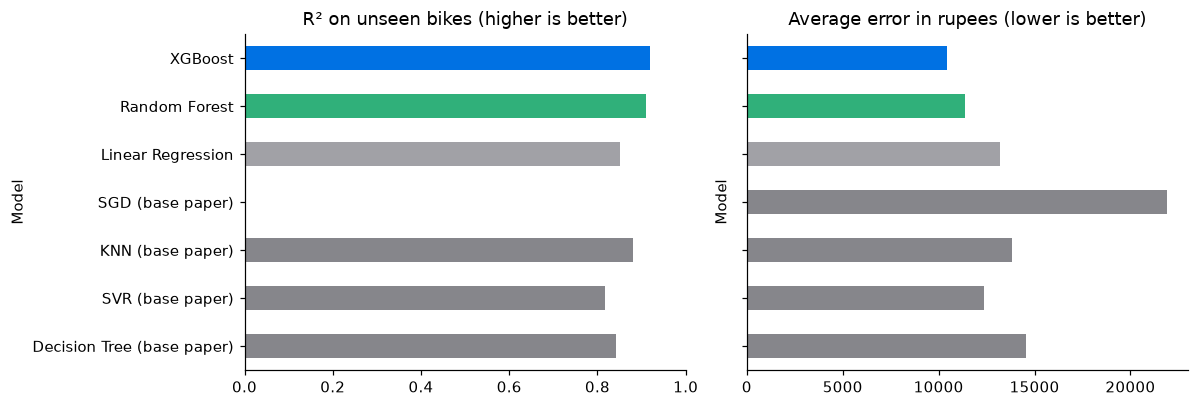

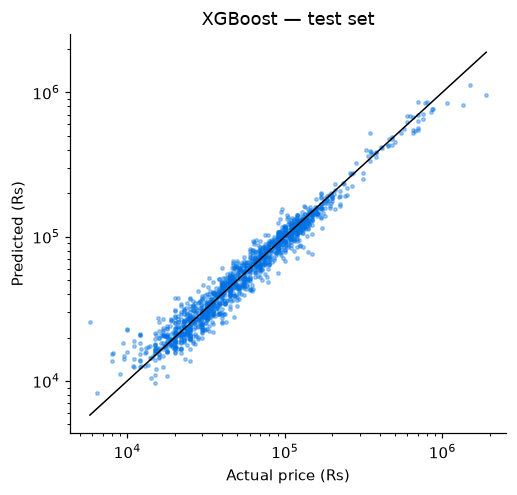

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
colors = ["#86868b"] * 4 + ["#a1a1a6", "#30b07a", "#0071e3"]
results["R2"].plot.barh(ax=ax[0], color=colors); ax[0].set_title("R² on unseen bikes (higher is better)"); ax[0].set_xlim(0, 1)
results["MAE (Rs)"].plot.barh(ax=ax[1], color=colors); ax[1].set_title("Average error in rupees (lower is better)"); ax[1].set_yticklabels([])
plt.tight_layout(); plt.savefig("figures/m4_model_comparison.png", dpi=150); plt.show()

xgb_pipe = fitted["XGBoost"]
yt, yp = np.expm1(yte), np.expm1(xgb_pipe.predict(Xte))
plt.figure(figsize=(4.8, 4.6)); plt.scatter(yt, yp, s=5, alpha=.35, color="#0071e3")
lim = [yt.min(), yt.max()]; plt.plot(lim, lim, "k-", lw=1); plt.xscale("log"); plt.yscale("log")
plt.xlabel("Actual price (Rs)"); plt.ylabel("Predicted (Rs)"); plt.title("XGBoost — test set")
plt.tight_layout(); plt.savefig("figures/m4_actual_vs_pred.png", dpi=150); plt.show()

## Module 5 — Road-tax side check (kept small)
Does knowing the state (and its road-tax rate) improve prices, and does the tax rate help on a state the model never saw?

In [7]:
def xgb_r2(cat, num, data=df):
    d = data.dropna(subset=num)
    Xa, ya = d[cat + num], np.log1p(d.price)
    a, b, c, e = train_test_split(Xa, ya, test_size=.2, random_state=42)
    ct = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse_output=False), cat), ("num", "passthrough", num)])
    p = Pipeline([("pre", ct), ("m", XGBRegressor(n_estimators=500, learning_rate=.06, max_depth=6, random_state=42, n_jobs=-1))]).fit(a, c)
    return r2_score(np.expm1(e), np.expm1(p.predict(b))), mean_absolute_error(np.expm1(e), np.expm1(p.predict(b)))

taxed = df[df.road_tax_rate.notna()]
base = ["age", "log_km", "owners", "power"]
tax_tbl = pd.DataFrame([("No location", *xgb_r2(["brand", "model"], base, taxed)),
                        ("State", *xgb_r2(["brand", "model", "state"], base, taxed)),
                        ("State + road-tax rate", *xgb_r2(["brand", "model", "state"], base + ["road_tax_rate"], taxed))],
                       columns=["Setup", "R2", "MAE (Rs)"]).set_index("Setup")
display(tax_tbl.style.format({"R2": "{:.4f}", "MAE (Rs)": "{:,.0f}"})) if "display" in dir() else print(tax_tbl)

out = []
for s in taxed.state.value_counts().index:
    tr, te = taxed[taxed.state != s], taxed[taxed.state == s]
    for label, num in [("no tax", base), ("with tax", base + ["road_tax_rate"])]:
        ct = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["brand", "model"]), ("num", "passthrough", num)])
        p = Pipeline([("pre", ct), ("m", XGBRegressor(n_estimators=400, learning_rate=.06, max_depth=6, random_state=42, n_jobs=-1))])
        p.fit(tr[["brand", "model"] + num], np.log1p(tr.price))
        out.append([s, label, mean_absolute_error(te.price, np.expm1(p.predict(te[["brand", "model"] + num])))])
loso = pd.DataFrame(out, columns=["held-out state", "setup", "MAE"]).pivot(index="held-out state", columns="setup", values="MAE")
loso["tax helps?"] = np.where(loso["with tax"] < loso["no tax"], "yes", "no")
loso.round(0)

                             R2      MAE (Rs)
Setup                                        
No location            0.940394  10172.413475
State                  0.945440   9732.340505
State + road-tax rate  0.941072   9878.826724


setup,no tax,with tax,tax helps?
held-out state,,,
Delhi,13216.0,13332.0,no
Gujarat,9396.0,9950.0,no
Haryana,7877.0,7556.0,yes
Karnataka,12546.0,11226.0,yes
Maharashtra,14710.0,14411.0,yes
Punjab,9960.0,10365.0,no
Rajasthan,7948.0,7940.0,yes
Tamil Nadu,12803.0,13145.0,no
Telangana,13408.0,12782.0,yes


## Module 6 — The 2026 test
The model above learned from ads posted in 2020-21. Here it prices **every matching used-bike ad live on BikeWale in Nov 2026**
(same official model names). Kaggle-era rupees are brought to 2026 with 5% a year. If the model "goes stale", the
median of actual ÷ predicted will be far from 1 — and that ratio becomes the calibration factor the website uses.

In [8]:
u = pd.read_csv(f"{DATA}/bikewale_used_2026.csv")
u = u.rename(columns={"makeName": "brand", "priceNumeric": "price", "kmNumeric": "km", "ownersId": "owners", "cityName": "city"})
u["model_name"] = u.modelName.str.replace(r"\[.*?\]", "", regex=True).str.replace(r"^(Old Generation|New|Old)\s+", "", regex=True).str.strip()
u["model"] = u.brand + " " + u.model_name
u["age"] = 2026 - u.makeYear
u = u[(u.price > 5_000) & (u.km.between(100, 150_000)) & (u.age.between(0, 20))]
print(f"{len(u):,} usable 2026 ads, {u.model.nunique()} models, {u.city.nunique()} cities; EV share {np.mean(u.fuel == 'Electric'):.1%}")

trained_models = set(df.model)
t26 = u[(u.fuel == "Petrol") & u.model.isin(trained_models)].copy()
t26["state"] = t26.city.map(dict(zip(cs.city, cs.state))).fillna("Other")
t26["log_km"] = np.log1p(t26.km)
t26["power"] = t26.model.map(df.groupby("model").power.median())
t26["owners"] = t26.owners.clip(1, 4)
SCALE = 1.05 ** 5
t26["pred"] = np.expm1(xgb_pipe.predict(t26[CAT + NUM])) * SCALE
t26["ratio"] = t26.price / t26.pred
calib = float(t26.ratio.median())
by_age = t26.groupby(pd.cut(t26.age, [-1, 1, 3, 5, 8, 12, 20])).ratio.median()
print(f"{len(t26):,} 2026 petrol ads of models the model knows")
print(f"Before calibration: MAE Rs {mean_absolute_error(t26.price, t26.pred):,.0f}, R² {r2_score(t26.price, t26.pred):.3f}, median actual/pred = {calib:.3f}")
t26["pred_cal"] = t26.pred * calib
print(f"After  calibration: MAE Rs {mean_absolute_error(t26.price, t26.pred_cal):,.0f}, R² {r2_score(t26.price, t26.pred_cal):.3f}, "
      f"within ±20%: {np.mean(np.abs(t26.pred_cal / t26.price - 1) <= .2):.1%}")
by_age

29,630 usable 2026 ads, 644 models, 1145 cities; EV share 3.2%
13,569 2026 petrol ads of models the model knows
Before calibration: MAE Rs 26,389, R² 0.361, median actual/pred = 1.083
After  calibration: MAE Rs 27,399, R² 0.337, within ±20%: 52.2%


age
(-1, 1]     0.959381
(1, 3]      1.012387
(3, 5]      1.075604
(5, 8]      1.155933
(8, 12]     1.169922
(12, 20]    1.150025
Name: ratio, dtype: float64

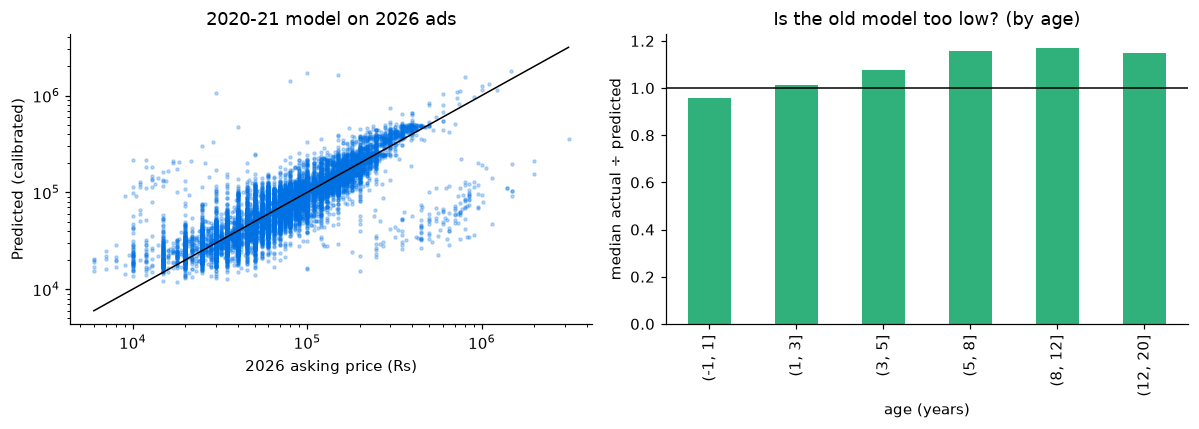

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(t26.price, t26.pred_cal, s=4, alpha=.25, color="#0071e3"); l = [t26.price.min(), t26.price.max()]
ax[0].plot(l, l, "k-", lw=1); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("2026 asking price (Rs)"); ax[0].set_ylabel("Predicted (calibrated)"); ax[0].set_title("2020-21 model on 2026 ads")
by_age.plot.bar(ax=ax[1], color="#30b07a"); ax[1].axhline(1, color="k", lw=1); ax[1].set_ylabel("median actual ÷ predicted")
ax[1].set_title("Is the old model too low? (by age)"); ax[1].set_xlabel("age (years)")
plt.tight_layout(); plt.savefig("figures/m6_2026_test.png", dpi=150); plt.show()
json.dump({"calibration": calib, "n": int(len(t26)), "by_age": {str(k): float(v) for k, v in by_age.items()}}, open("figures/m6_calibration.json", "w"), indent=1)

## Module 7 — EV vs petrol depreciation (2026 ads, same variant)
`log(price) ~ age + log(1+km) + EV×age + variant + city`, standard errors clustered by variant.
The **variant** term (BikeWale version id) absorbs brand, engine, fuel and new price, so the age slope is how fast *the same variant* loses value.

In [10]:
import statsmodels.formula.api as smf
e = u[u.fuel.isin(["Petrol", "Electric"]) & (u.age <= 7)].copy()
e["ev"] = (e.fuel == "Electric").astype(int)
e["log_price"] = np.log(e.price); e["log_km"] = np.log1p(e.km)
e["ola"] = (e.brand.str.upper() == "OLA").astype(int)
e["scooter"] = (e.bodyStyleId.astype(str) == "5").astype(int)
vc = e.versionId.value_counts(); e = e[e.versionId.map(vc) >= 2]
cc_ = e.city.value_counts(); e["city2"] = np.where(e.city.map(cc_) >= 30, e.city, "other")

def ev_gap(d, label):
    m = smf.ols("log_price ~ age + log_km + ev:age + C(versionId) + C(city2)", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d.versionId)[0]})
    pet = (np.exp(m.params["age"]) - 1) * 100
    evr = (np.exp(m.params["age"] + m.params["ev:age"]) - 1) * 100
    return {"Check": label, "Ads": len(d), "EV ads": int(d.ev.sum()), "Petrol %/yr": round(pet, 1), "EV %/yr": round(evr, 1),
            "EV − petrol (pts)": round(evr - pet, 1), "p": round(m.pvalues["ev:age"], 3)}

ev_tbl = pd.DataFrame([ev_gap(e, "All two-wheelers, age ≤ 7"),
                       ev_gap(e[e.ola == 0], "Without Ola"),
                       ev_gap(e[(e.ev == 0) | (e.ola == 1)], "Ola only vs petrol"),
                       ev_gap(e[e.scooter == 1], "Scooters only")]).set_index("Check")
ev_tbl

,Ads,EV ads,Petrol %/yr,EV %/yr,EV − petrol (pts),p
Check,,,,,,
"All two-wheelers, age ≤ 7",20014,847,-6.3,-12.0,-5.7,0.001
Without Ola,19627,460,-6.3,-13.0,-6.7,0.002
Ola only vs petrol,19554,387,-6.3,-10.6,-4.4,0.125
Scooters only,3506,717,-7.6,-12.9,-5.2,0.010


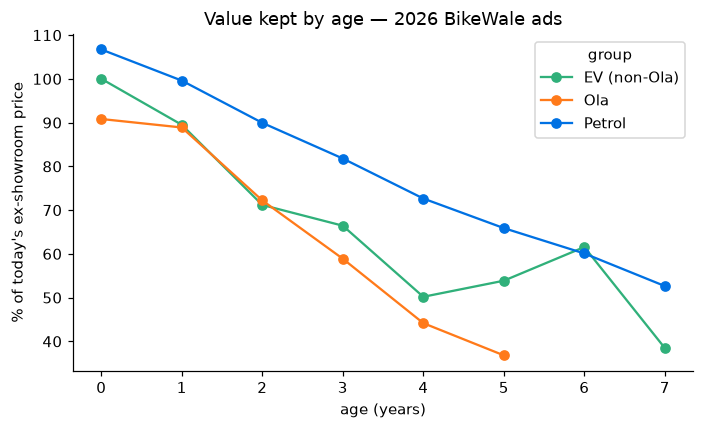

In [11]:
kept = e.merge(cat[["brand", "model", "new_price"]].assign(model_name=cat.model), left_on=["brand", "model_name"], right_on=["brand", "model_name"], how="inner")
kept["kept"] = kept.price / kept.new_price
kept["group"] = np.where(kept.ev == 0, "Petrol", np.where(kept.ola == 1, "Ola", "EV (non-Ola)"))
curve = kept[kept.kept.between(.1, 1.5)].groupby(["group", "age"]).kept.median().unstack(0)
ax = curve.mul(100).plot(figsize=(6.5, 4), marker="o", color={"Petrol": "#0071e3", "EV (non-Ola)": "#30b07a", "Ola": "#ff7a1a"})
ax.set_ylabel("% of today's ex-showroom price"); ax.set_xlabel("age (years)"); ax.set_title("Value kept by age — 2026 BikeWale ads")
plt.tight_layout(); plt.savefig("figures/m7_value_kept.png", dpi=150); plt.show()

## Module 8 — SHAP: what drives the price?

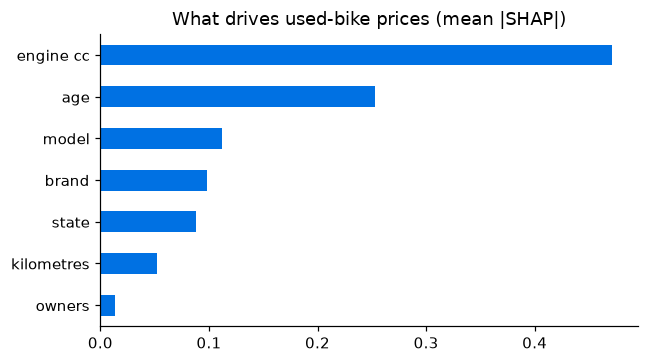

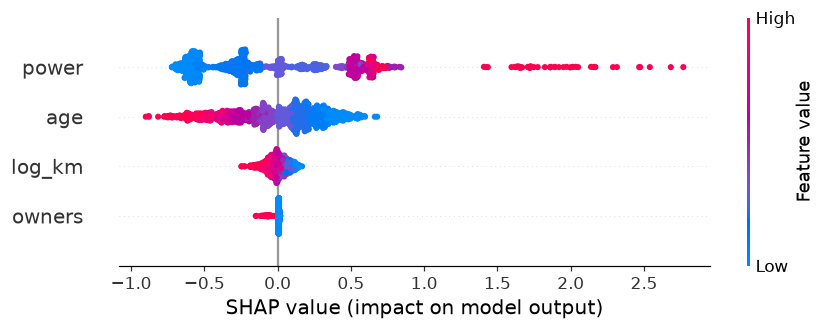

In [12]:
import shap
Z = xgb_pipe.named_steps["pre"].transform(Xte)
names = xgb_pipe.named_steps["pre"].get_feature_names_out()
explainer = shap.TreeExplainer(xgb_pipe.named_steps["m"])
sv = explainer.shap_values(Z)
groups = [next(c for c in CAT if n.startswith(f"cat__{c}_")) if n.startswith("cat__") else n.replace("num__", "") for n in names]
imp = pd.Series(np.abs(sv).mean(0), index=groups).groupby(level=0).sum().sort_values()
imp.rename({"power": "engine cc", "log_km": "kilometres", "model": "model", "brand": "brand"}).plot.barh(figsize=(6, 3.4), color="#0071e3")
plt.title("What drives used-bike prices (mean |SHAP|)"); plt.tight_layout(); plt.savefig("figures/m8_shap_importance.png", dpi=150); plt.show()

num_idx = [i for i, n in enumerate(names) if n.startswith("num__")]
shap.summary_plot(sv[:, num_idx], Z[:, num_idx], feature_names=[names[i].replace("num__", "") for i in num_idx], show=False)
plt.tight_layout(); plt.savefig("figures/m8_shap_beeswarm.png", dpi=150); plt.show()

## Module 9 — Main models: trained on live 2026 listings (cars and two-wheelers)
The models the website uses. Trained on 30,306 BikeWale two-wheeler ads and 91,748 CarWale car ads (Nov 2026).
* **Features:** brand, model, exact variant, the variant's new price, fuel, body type, gearbox, state, city, seller type, age, km, owners,
  and (v2) **the Indian tax a new one paid the year it was bought** — from our tax history file `tax_history.py` (1990-2026:
  excise + VAT before July 2017, GST + cess after, GST 2.0 from 22 Sep 2025)
* **Monotone rules:** the price never rises with age, km or owners, and never falls as the new price rises
* **Model:** XGBoost with native categories; several boosted models with different random seeds, averaged
* **Benchmarks:** a simple rule (new price × typical share kept at that age) and, for cars, **CarWale's own valuation** on the same ads
* **Noise floor:** how far asking prices sit apart for the same variant, year and seller — roughly the best any model can do

Takes about 10 minutes on Colab (the car data is large).

In [13]:
import xgboost as xgb
NOW = 2026
MCATS = ["brand", "model_key", "variant", "fuel", "body", "transmission", "state", "city", "seller"]
sys.path.insert(0, DATA)                          # tax_history.py ships in the data zip
from tax_history import national_tax
from datetime import date
TAX_NUMS = ["tax_then", "tax_shift"]             # tax rate when bought; log(1 + then) - log(1 + today)
MNUMS = ["age", "log_km", "owners", "log_new", "log_new_model"] + TAX_NUMS
MONO = {"age": -1, "log_km": -1, "owners": -1, "log_new": 1, "log_new_model": 1}
SIZE = {"bike": (5, 10), "car": (3, 8)}        # (models averaged, tree depth) -- same as the website
city_state_full = pd.read_csv(f"{DATA}/city_state_full.csv").drop_duplicates("city")
CITY2STATE = dict(zip(city_state_full.city, city_state_full.state))

def clean_model(s):
    return (s.astype(str).str.replace(r"\[.*?\]", "", regex=True)
            .str.replace(r"^(Old Generation|New|Old)\s+", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip())

def fuel_of(s):
    s = s.fillna("Petrol").astype(str).str.lower()   # hybrids first: "Hybrid (Electric + Petrol)" is not electric
    return np.select([s.str.contains("hybrid"), s.str.contains("electric"), s.str.contains("diesel"), s.str.contains("cng"),
                      s.str.contains("lpg")], ["Hybrid", "Electric", "Diesel", "CNG", "LPG"], "Petrol")

def load_market(kind):
    u = pd.read_csv(f"{DATA}/market_{kind}_ads.csv", low_memory=False)
    n0 = len(u)
    u = u.drop_duplicates("stockId").rename(columns={"makeName": "brand", "priceNumeric": "price", "kmNumeric": "km",
                                                     "ownersId": "owners", "cityName": "city"})
    u["model_key"] = u.brand + " | " + clean_model(u.modelName)
    u["variant"] = u.versionId.astype("Int64").astype(str)
    u["age"] = (NOW - u.makeYear).clip(lower=0)
    u["fuel"] = fuel_of(u.fuel)
    t = u.transmission.fillna("").astype(str).str.lower()
    u["transmission"] = np.where(t.str.contains("auto|amt|cvt|dct"), "Automatic", np.where(t == "", "NA", "Manual")) if kind == "car" else "NA"
    u["body"] = u.bodyStyleId.astype(str)
    if kind == "bike":
        u["body"] = np.where(u.body == "5", "scooter", "motorcycle")
    u["state"] = u.city.map(CITY2STATE).fillna("Other")
    u["seller"] = u.sellerType.map({1: "dealer", 2: "individual"}).fillna("unknown")
    u["owners"] = u.owners.fillna(1).clip(1, 4)
    if kind == "car":
        u["new_price"] = pd.to_numeric(u.onRoadPrice, errors="coerce").where(lambda x: x > 50_000)   # variant's new on-road price
        catm = pd.read_csv(f"{DATA}/car_catalog.csv")
    else:
        v = pd.read_csv(f"{DATA}/bike_variants.csv")
        u["new_price"] = u.versionId.map(dict(zip(v.versionId, v.ex_showroom)))                      # variant's ex-showroom price
        catm = pd.read_csv(f"{DATA}/bike_catalog.csv")
    u["new_price_model"] = u.model_key.map(dict(zip(catm.brand + " | " + catm.model, catm.new_price)))
    u["new_price"] = u.new_price.fillna(u.groupby("model_key").new_price.transform("median")).fillna(u.new_price_model)
    u = u[(u.price >= (40_000 if kind == "car" else 5_000)) & u.km.between(0, 300_000 if kind == "car" else 150_000) & (u.age <= 25)]
    r = u.price / u.new_price
    u = u[~((r > 1.6) | (r < 0.03))]                                                   # typos vs the new price
    u = u.drop_duplicates(["model_key", "variant", "makeYear", "km", "price", "city"])  # re-posted ads
    u["lp"] = np.log(u.price)
    u["ag"] = pd.cut(u.age, [-1, 1, 3, 5, 8, 12, 30])
    g = u.groupby(["model_key", "ag"], observed=True).lp
    q1, q3, n = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75)), g.transform("size")
    u = u[(n < 10) | u.lp.between(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))]       # outliers per model + age group
    add_tax(u, kind, dict(zip(catm.brand + " | " + catm.model, catm.cc)) if kind == "bike" else None)
    u["log_km"] = np.log1p(u.km); u["log_new"] = np.log(u.new_price); u["log_new_model"] = np.log(u.new_price_model)
    for col, k in [("variant", 3), ("city", 25), ("model_key", 3)]:                   # rare categories -> missing
        vc = u[col].value_counts(); u.loc[u[col].map(vc) < k, col] = np.nan
    print(f"{kind}: {n0:,} ads loaded -> {len(u):,} after cleaning, {u.model_key.nunique()} models, {int((u.fuel == 'Electric').sum()):,} electric")
    return u.reset_index(drop=True)

def add_tax(u, kind, cc_map=None):
    """tax_then / tax_shift per ad. Engine size: bikes the model's cc (catalogue), cars from the variant name in litres."""
    if kind == "car":
        eng = pd.to_numeric(u.versionName.astype(str).str.extract(r"(?<![\d.])([0-4]\.\d)(?![\d])", expand=False), errors="coerce")
        body = u.bodyStyleId.astype(str)
    else:
        eng = pd.to_numeric(u.model_key.map(cc_map), errors="coerce")
        body = pd.Series("", index=u.index)
    memo, out = {}, []
    for y, e, f, b in zip(u.makeYear.astype(int), eng.round(2), u.fuel, body):
        k = (y, e, f, b)
        if k not in memo:
            ee = None if e != e else float(e)
            t = national_tax(kind, date(y, 7, 1), ee, f, b)["rate"]; n = national_tax(kind, date(NOW, 7, 1), ee, f, b)["rate"]
            memo[k] = (t, np.log1p(t) - np.log1p(n))
        out.append(memo[k])
    u["tax_then"] = [x[0] for x in out]; u["tax_shift"] = [x[1] for x in out]

def mframe(df, cats, nums=None):
    X = df[MCATS + (nums or MNUMS)].copy()
    for c in MCATS:
        X[c] = pd.Categorical(X[c], categories=cats[c])
    return X

def mmetrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); e = np.abs(p / y - 1)
    return {"Ads": len(y), "Typical miss": np.median(e), "Within ±10%": np.mean(e <= .1), "Within ±20%": np.mean(e <= .2),
            "R2 (log)": 1 - np.sum((np.log(y) - np.log(p)) ** 2) / np.sum((np.log(y) - np.log(y).mean()) ** 2)}

def train_market(kind, nums=None, u=None):
    nums = nums or MNUMS
    u = load_market(kind) if u is None else u
    cats = {c: sorted(u[c].dropna().astype(str).unique().tolist()) for c in MCATS}
    tr, te = train_test_split(u, test_size=0.2, random_state=42)
    tr2, va = train_test_split(tr, test_size=0.15, random_state=7)
    seeds, depth = SIZE[kind]
    params = {"objective": "reg:squarederror", "tree_method": "hist", "max_cat_to_onehot": 1, "max_cat_threshold": 16,
              "eta": 0.03, "max_depth": depth, "min_child_weight": 5, "subsample": 0.8, "colsample_bytree": 0.7, "lambda": 3.0,
              "monotone_constraints": "(" + ",".join(str(MONO.get(f, 0)) for f in MCATS + nums) + ")"}
    dtr2 = xgb.DMatrix(mframe(tr2, cats, nums), tr2.lp, enable_categorical=True)
    dva = xgb.DMatrix(mframe(va, cats, nums), va.lp, enable_categorical=True)
    rounds = [xgb.train({**params, "seed": s}, dtr2, 6000, evals=[(dva, "va")], early_stopping_rounds=200,
                        verbose_eval=False).best_iteration + 1 for s in range(seeds)]
    dtr = xgb.DMatrix(mframe(tr, cats, nums), tr.lp, enable_categorical=True)
    boosters = [xgb.train({**params, "seed": s}, dtr, num_boost_round=r) for s, r in zip(range(seeds), rounds)]
    dte = xgb.DMatrix(mframe(te, cats, nums), enable_categorical=True)
    pt = np.exp(np.mean([b.predict(dte) for b in boosters], axis=0))
    rows = {"All test ads": mmetrics(te.price, pt)}
    seg = te.fuel if kind == "car" else te.fuel + " " + te.body
    for s_ in sorted(seg.unique()):
        m = (seg == s_).values
        if m.sum() >= 30:
            rows[f"  {s_}"] = mmetrics(te.price[m], pt[m])
    kept = (tr.price / tr.new_price).groupby(tr.age).median()
    base = te.new_price * te.age.map(kept).fillna(kept.median()); ok = base.notna().values
    rows["Simple rule: new price × typical share kept"] = mmetrics(te.price[ok], base[ok])
    if kind == "car":
        vm = (te.valuationPrice > 0).values
        rows["CarWale's own valuation (same ads)"] = mmetrics(te.price[vm], te.valuationPrice[vm])
        rows["Our model on those same ads"] = mmetrics(te.price[vm], pt[vm])
    d = u.dropna(subset=["variant"]); g = d.groupby(["variant", "makeYear", "seller"]).price
    cell, n = g.transform("median"), g.transform("size")
    floor = float(np.median(np.abs(d.price[n >= 5] / cell[n >= 5] - 1)))
    out = pd.DataFrame(rows).T
    print(f"noise floor ({kind}): asking prices for the same variant, year and seller sit {floor:.1%} apart (median)")
    return out, floor, boosters, cats, te, u

market_results, floors, market_data = {}, {}, {}
for kind in ("car", "bike"):
    market_results[kind], floors[kind], *_, market_data[kind] = train_market(kind)
    display(market_results[kind].style.format({"Ads": "{:,.0f}", "Typical miss": "{:.1%}", "Within ±10%": "{:.1%}",
                                               "Within ±20%": "{:.1%}", "R2 (log)": "{:.3f}"}))

car: 91,748 ads loaded -> 88,800 after cleaning, 494 models, 1,632 electric


noise floor (car): asking prices for the same variant, year and seller sit 8.7% apart (median)


,Ads,Typical miss,Within ±10%,Within ±20%,R2 (log)
All test ads,"17,760",8.3%,57.2%,83.0%,0.966
CNG,613,6.2%,70.6%,88.9%,0.950
Diesel,"6,387",8.7%,55.5%,81.7%,0.959
Electric,342,7.5%,64.0%,88.0%,0.951
Hybrid,218,5.2%,75.7%,94.5%,0.982
LPG,43,16.5%,37.2%,53.5%,0.449
Petrol,"10,157",8.4%,56.9%,83.2%,0.963
Simple rule: new price × typical share kept,"17,709",15.2%,35.6%,61.3%,0.905
CarWale's own valuation (same ads),"16,650",11.3%,45.2%,73.2%,0.949
Our model on those same ads,"16,650",8.2%,57.9%,83.8%,0.969


bike: 30,306 ads loaded -> 28,062 after cleaning, 464 models, 891 electric


noise floor (bike): asking prices for the same variant, year and seller sit 11.1% apart (median)


,Ads,Typical miss,Within ±10%,Within ±20%,R2 (log)
All test ads,"5,613",12.4%,42.1%,69.2%,0.871
Electric motorcycle,31,5.7%,64.5%,83.9%,0.922
Electric scooter,138,14.4%,33.3%,59.4%,0.602
Petrol motorcycle,"4,532",12.2%,43.0%,69.7%,0.869
Petrol scooter,912,13.4%,38.5%,67.8%,0.804
Simple rule: new price × typical share kept,"4,014",14.0%,37.0%,65.9%,0.861


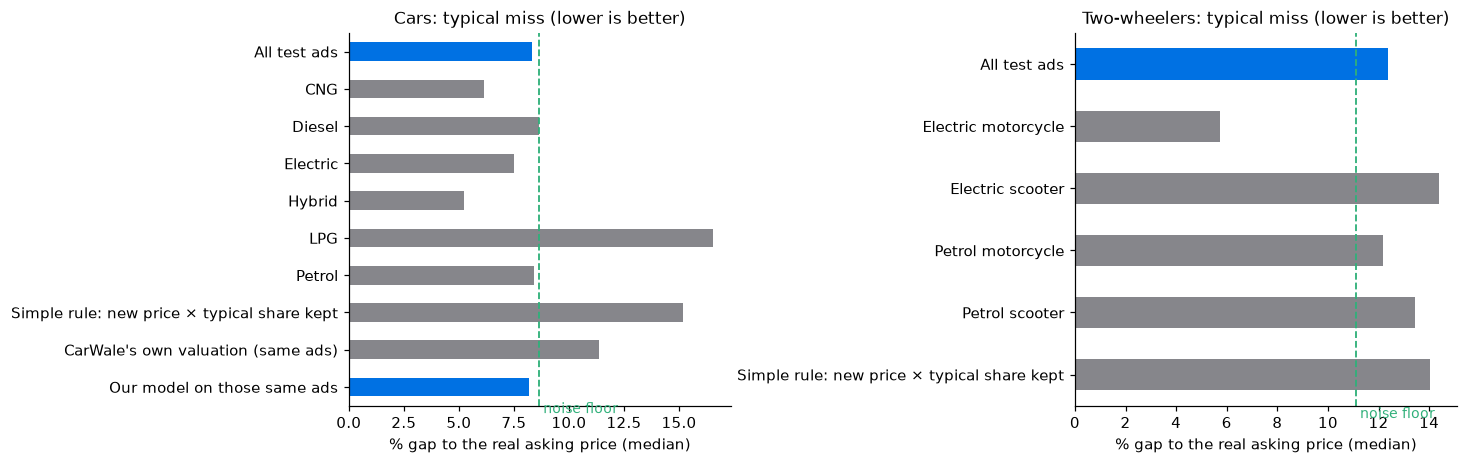

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"wspace": 0.9})
for a, kind in zip(ax, ("car", "bike")):
    r = market_results[kind]["Typical miss"].iloc[::-1] * 100
    colors = ["#0071e3" if i.startswith("All") or i.startswith("Our") else "#86868b" for i in r.index]
    r.plot.barh(ax=a, color=colors)
    a.axvline(floors[kind] * 100, color="#30b07a", ls="--", lw=1.2)
    a.text(floors[kind] * 100, -0.7, " noise floor", color="#30b07a", fontsize=9)
    a.set_title(("Cars" if kind == "car" else "Two-wheelers") + ": typical miss (lower is better)", fontsize=11)
    a.set_xlabel("% gap to the real asking price (median)")
plt.savefig("figures/m9_market_models.png", dpi=150, bbox_inches="tight"); plt.show()

## Module 9b — India's tax history (1990-2026) and whether it helps the model
`tax_history.py` stores the national tax on a NEW vehicle for every year since 1990, with a source and a confidence level
for each rule (pre-2008 rates are rough). The website shows it on the Price tab, and the v2 models above use it as an input.
Below: the rates over time, then the two-wheeler model trained **with and without** the tax inputs on the same split.

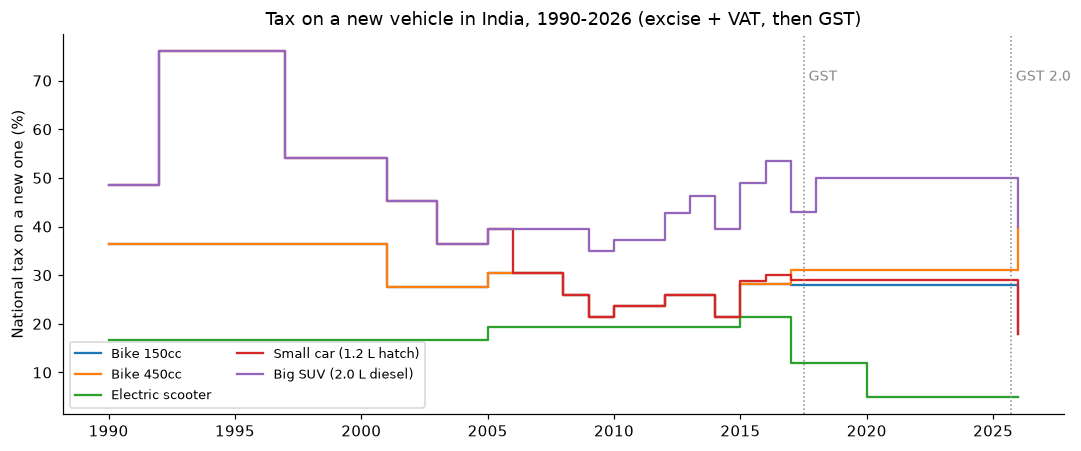

In [15]:
yrs = list(range(1990, 2027))
cases = {"Bike 150cc": ("bike", 150, "Petrol", ""), "Bike 450cc": ("bike", 450, "Petrol", ""), "Electric scooter": ("bike", None, "Electric", ""),
         "Small car (1.2 L hatch)": ("car", 1.2, "Petrol", "3"), "Big SUV (2.0 L diesel)": ("car", 2.0, "Diesel", "11")}
plt.figure(figsize=(10, 4.2))
for name, (k, e, f, b) in cases.items():
    plt.step(yrs, [national_tax(k, date(y, 7, 1), e, f, b)["rate"] * 100 for y in yrs], where="post", label=name)
for x, t in [(2017.5, "GST"), (2025.7, "GST 2.0")]:
    plt.axvline(x, color="#86868b", ls=":", lw=1); plt.text(x + .2, 70, t, color="#86868b", fontsize=9)
plt.ylabel("National tax on a new one (%)"); plt.title("Tax on a new vehicle in India, 1990-2026 (excise + VAT, then GST)")
plt.legend(fontsize=8.5, ncol=2); plt.tight_layout(); plt.savefig("figures/m9b_tax_history.png", dpi=150); plt.show()

In [16]:
base_nums = [n for n in MNUMS if n not in TAX_NUMS]
without, *_ = train_market("bike", nums=base_nums, u=market_data["bike"])
cmp_tbl = pd.DataFrame({"Without tax history (v1)": without.loc["All test ads"], "With tax history (v2)": market_results["bike"].loc["All test ads"]}).T
display(cmp_tbl.style.format({"Ads": "{:,.0f}", "Typical miss": "{:.2%}", "Within ±10%": "{:.1%}", "Within ±20%": "{:.1%}", "R2 (log)": "{:.4f}"}))
print("A change under ~0.3 points is noise: the year already tells the model most of what the tax rate does.")
cmp_tbl.round(4).to_csv("figures/m9b_tax_feature_bike.csv")

noise floor (bike): asking prices for the same variant, year and seller sit 11.1% apart (median)


,Ads,Typical miss,Within ±10%,Within ±20%,R2 (log)
Without tax history (v1),"5,613",12.41%,42.3%,69.3%,0.8704
With tax history (v2),"5,613",12.37%,42.1%,69.2%,0.8710


A change under ~0.3 points is noise: the year already tells the model most of what the tax rate does.


## Module 10 — Save tables for the report

In [17]:
results.round(4).to_csv("figures/m4_results.csv"); tax_tbl.round(4).to_csv("figures/m5_road_tax.csv")
loso.round(0).to_csv("figures/m5_loso.csv"); ev_tbl.to_csv("figures/m7_ev_vs_petrol.csv")
for kind in market_results:
    market_results[kind].round(4).to_csv(f"figures/m9_market_{kind}.csv")
print("Saved:", sorted(os.listdir("figures")))
if IN_COLAB:
    import shutil; shutil.make_archive("resaleiq_figures", "zip", "figures")
    from google.colab import files; files.download("resaleiq_figures.zip")

Saved: ['m4_actual_vs_pred.png', 'm4_model_comparison.png', 'm4_results.csv', 'm5_loso.csv', 'm5_road_tax.csv', 'm6_2026_test.png', 'm6_calibration.json', 'm7_ev_vs_petrol.csv', 'm7_value_kept.png', 'm8_shap_beeswarm.png', 'm8_shap_importance.png', 'm9_market_bike.csv', 'm9_market_car.csv', 'm9_market_models.png', 'm9b_tax_feature_bike.csv', 'm9b_tax_history.png']
